SetUp

In [1]:
# pip install opencv-python matplotlib numpy pandas

In [2]:
import pickle
from pathlib import Path

import cv2 as cv
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

%config InlineBackend.figure_formats = ['jpeg']

ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
SEG_PKL = ROOT / 'data' / 'processed' / 'dataset_seg.pkl'
PCD_PKL = ROOT / 'data' / 'processed' / 'dataset_pcd.pkl'

FLOOR, MOTOR, IGNORE = 0, 1, 255
CLASS_COLORS = {FLOOR: (0, 200, 0), MOTOR: (0, 0, 230), IGNORE: (150, 150, 150)}
rng = np.random.default_rng(0)

Step 1: Load Dataset

In [3]:
with open(SEG_PKL, 'rb') as f:
    data = pickle.load(f)

X, Y, meta, geo = data['X'], data['Y'], data['meta'], data['geo']

print('X:', X.shape, X.dtype)
print('Y:', Y.shape, Y.dtype)
print('pixels  floor:', int(np.sum(Y == FLOOR)), '| motorcycle:', int(np.sum(Y == MOTOR)), '| ignore:', int(np.sum(Y == IGNORE)))
pd.crosstab(meta['weather'], meta['split'], margins=True)

X: (92, 540, 960, 3) uint8
Y: (92, 540, 960) uint8
pixels  floor: 5136886 | motorcycle: 12999420 | ignore: 29556494


split,test,train,val,All
weather,,,,
cloudy,0,9,0,9
dusk,9,0,0,9
rain,0,18,9,27
sunny,17,26,4,47
All,26,53,13,92


dataset berisi frame 960 × 540 (`X`), mask nya (`Y`) dan meta per frame. pembagian train / val / test sudah dibuat per hari di notebook sebelumnya. di notebook ini statistik warna hanya diambil dari **train**, threshold dipilih di **val**, dan angka akhir dilaporkan di **test**, supaya hasil nya tidak bocor.

Step 2: Color Spaces

In [4]:
def to_spaces(img):
    gray = cv.cvtColor(img, cv.COLOR_BGR2GRAY)
    hsv = cv.cvtColor(img, cv.COLOR_BGR2HSV)       # H 0-179, S 0-255, V 0-255
    lab = cv.cvtColor(img, cv.COLOR_BGR2LAB)       # L, a (green-red), b (blue-yellow), all 0-255
    return {'gray': gray, 'H': hsv[:, :, 0], 'S': hsv[:, :, 1], 'V': hsv[:, :, 2],
            'L': lab[:, :, 0], 'a': lab[:, :, 1], 'b': lab[:, :, 2]}

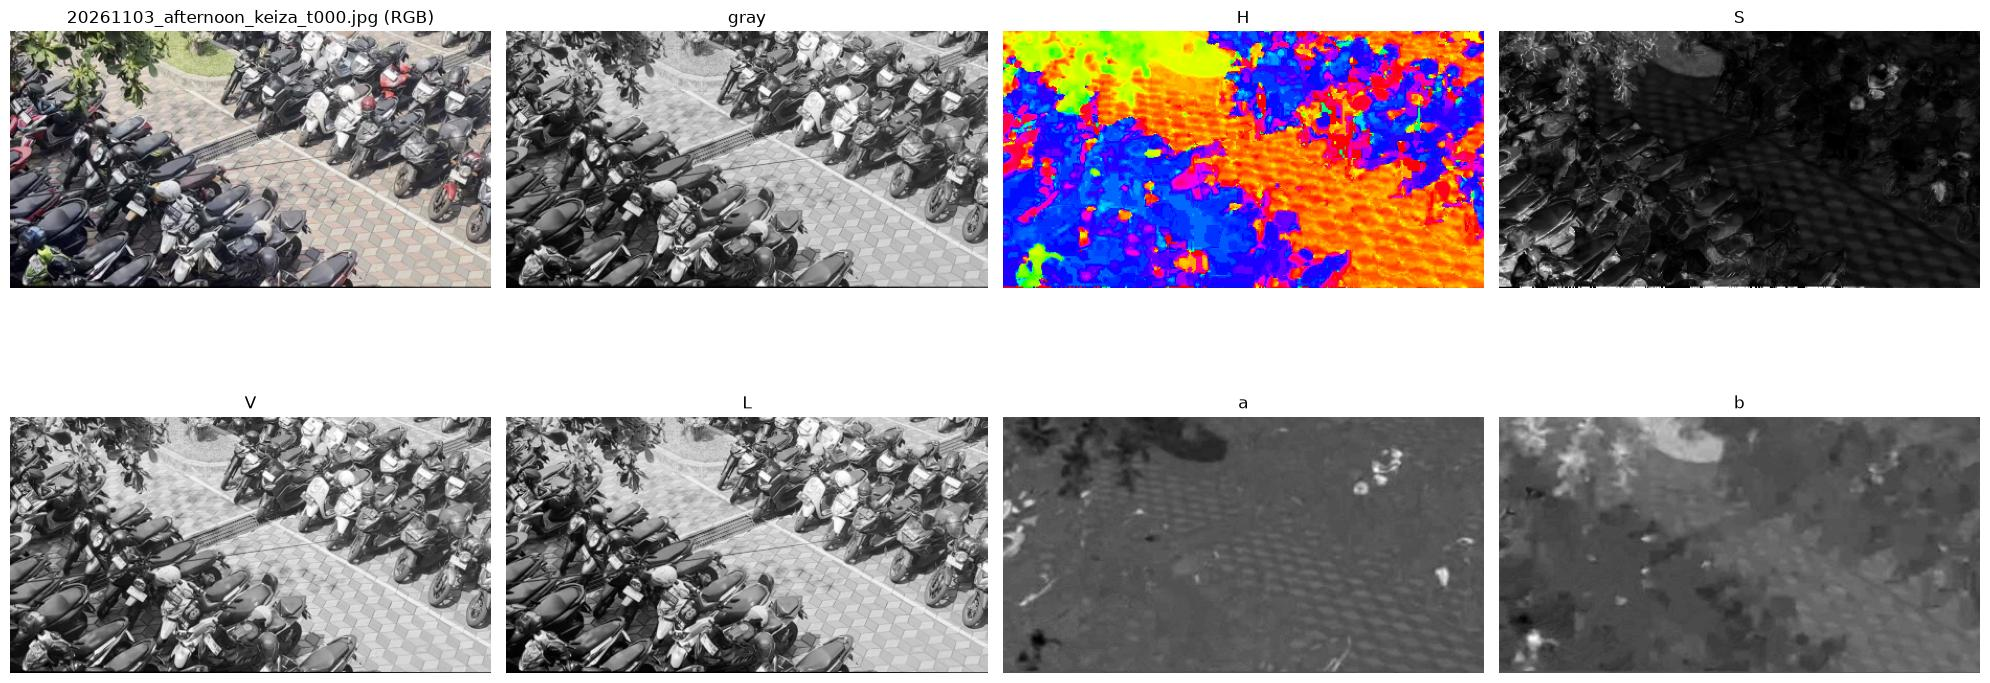

In [5]:
DEMO = int(np.argmax(meta['weather'] == 'sunny'))
img = X[DEMO]
spaces = to_spaces(img)

ys, xs = np.where(Y[DEMO] != IGNORE)
y0, x0 = max(0, int(ys.mean()) - 130), max(0, int(xs.mean()) - 230)   # zoom on the ROI

plt.figure(figsize=(20, 9))
plt.subplot(2, 4, 1)
plt.imshow(img[y0:y0 + 260, x0:x0 + 460, ::-1])
plt.title(f"{meta['frame'][DEMO]} (RGB)")
plt.axis('off')
for k, name in enumerate(['gray', 'H', 'S', 'V', 'L', 'a', 'b']):
    plt.subplot(2, 4, k + 2)
    plt.imshow(spaces[name][y0:y0 + 260, x0:x0 + 460], cmap='hsv' if name == 'H' else 'gray')
    plt.title(name)
    plt.axis('off')
plt.tight_layout()
plt.show()

- **gray** hanya menyimpan kecerahan, jadi motor hitam dan ubin abu-abu gelap bisa terlihat sama.
- **hsv** memisahkan warna (**H**ue, 0–179 di opencv), kemurnian warna (**S**aturation) dan kecerahan (**V**alue). ide nya: bayangan dan sore hari terutama mengubah v, sedangkan h relatif tetap.
- **lab** memisahkan kecerahan (**L**) dari dua sumbu warna: **a** (hijau ↔ merah) dan **b** (biru ↔ kuning). paving merah bata punya nilai a yang tinggi.

Step 3: Hue Wrap-Around

In [6]:
def sample_pixels(split, per_frame=20000):
    # random labeled pixels of every frame in one split -> one table, one row per pixel
    rows = []
    for i in np.where(meta['split'] == split)[0]:
        valid = np.flatnonzero(Y[i] != IGNORE)
        pick = rng.choice(valid, min(per_frame, len(valid)), replace=False)
        sp = to_spaces(X[i])
        part = {name: sp[name].ravel()[pick] for name in sp}
        part['label'] = Y[i].ravel()[pick]
        part['weather'] = meta['weather'][i]
        rows.append(pd.DataFrame(part))
    return pd.concat(rows, ignore_index=True)


train_px = sample_pixels('train')
print('sampled train pixels:', len(train_px), '| floor:', int(np.sum(train_px['label'] == FLOOR)),
      '| motorcycle:', int(np.sum(train_px['label'] == MOTOR)))

sampled train pixels: 1060000 | floor: 278499 | motorcycle: 781501


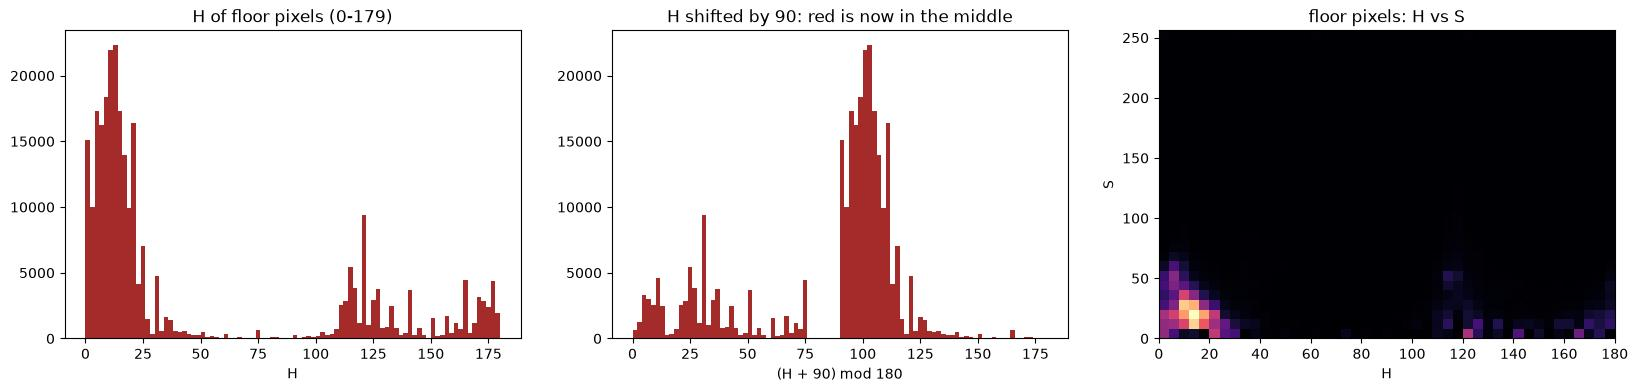

floor pixels with H < 15 or H > 165 (red)  : 52.4%
floor pixels with S < 40 (hue is unreliable): 82.8%


In [7]:
floor_h = train_px.loc[train_px['label'] == FLOOR, 'H']
floor_s = train_px.loc[train_px['label'] == FLOOR, 'S']

plt.figure(figsize=(20, 4))
plt.subplot(1, 3, 1)
plt.hist(floor_h, bins=90, range=(0, 180), color='brown')
plt.title('H of floor pixels (0-179)')
plt.xlabel('H')
plt.subplot(1, 3, 2)
plt.hist((floor_h + 90) % 180, bins=90, range=(0, 180), color='brown')
plt.title('H shifted by 90: red is now in the middle')
plt.xlabel('(H + 90) mod 180')
plt.subplot(1, 3, 3)
plt.hist2d(floor_h, floor_s, bins=[45, 32], range=[[0, 180], [0, 256]], cmap='magma')
plt.title('floor pixels: H vs S')
plt.xlabel('H')
plt.ylabel('S')
plt.show()

print('floor pixels with H < 15 or H > 165 (red)  :', f"{100 * np.mean((floor_h < 15) | (floor_h > 165)):.1f}%")
print('floor pixels with S < 40 (hue is unreliable):', f"{100 * np.mean(floor_s < 40):.1f}%")

hue berbentuk **lingkaran**: merah ada di dua ujung (h ≈ 0 dan h ≈ 179), jadi ubin merah yang sama bisa terbaca h = 2 atau h = 177. kalau h dipakai langsung sebagai angka, kedua nilai ini terlihat sangat jauh padahal warna nya sama. setelah digeser 90, merah pindah ke tengah dan histogram nya menjadi satu puncak. cara lain adalah memakai cos(h) dan sin(h).

masalah kedua: **hue tidak berarti kalau saturasi nya rendah**. ubin abu-abu, motor hitam, putih dan silver hampir tidak punya warna, jadi h nya acak (terlihat sebagai garis horizontal di bagian bawah histogram h vs s). karena itu h harus selalu dipakai bersama s.

Step 4: Channel Histograms per Class

In [8]:
def overlap(a, b, bins=64, value_range=(0, 256)):
    # overlap of the two normalised histograms: 0 = fully separated, 1 = identical
    ha, _ = np.histogram(a, bins=bins, range=value_range)
    hb, _ = np.histogram(b, bins=bins, range=value_range)
    return np.sum(np.minimum(ha / ha.sum(), hb / hb.sum()))


train_px['H shifted'] = (train_px['H'].astype(int) + 90) % 180
channels = ['gray', 'H shifted', 'S', 'V', 'L', 'a', 'b']

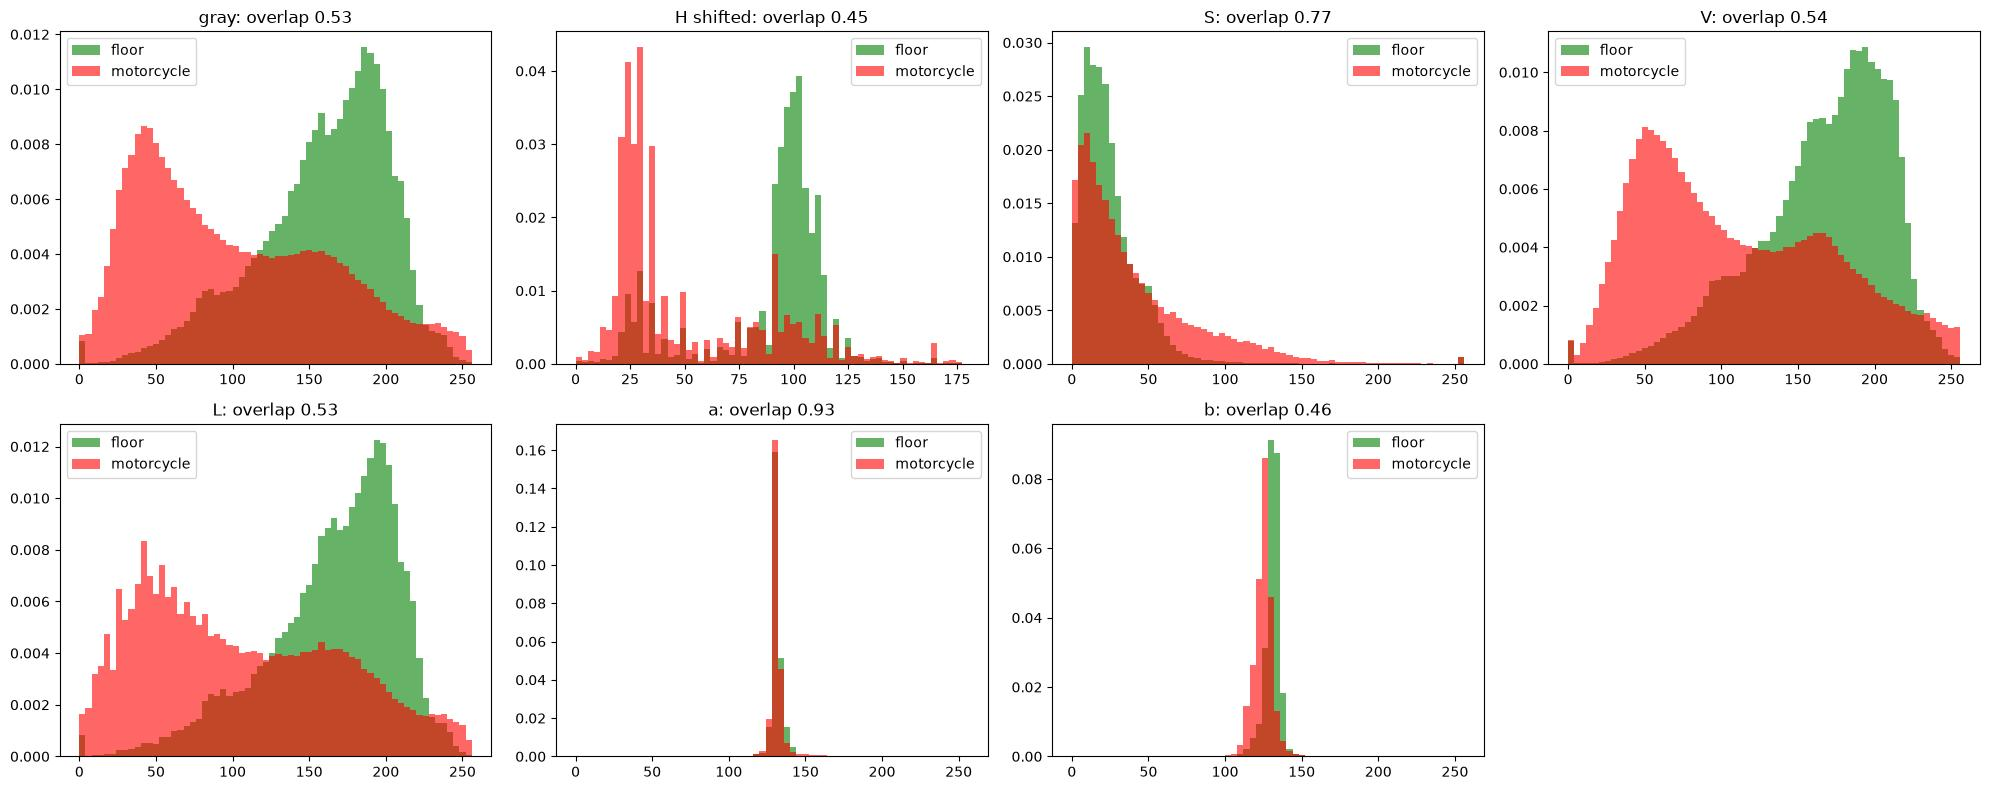

,channel,overlap
0,H shifted,0.449
1,b,0.462
2,gray,0.532
3,L,0.533
4,V,0.542
5,S,0.774
6,a,0.934


In [9]:
floor_px = train_px[train_px['label'] == FLOOR]
motor_px = train_px[train_px['label'] == MOTOR]

plt.figure(figsize=(20, 8))
scores = []
for k, name in enumerate(channels):
    value_range = (0, 180) if name == 'H shifted' else (0, 256)
    ov = overlap(floor_px[name], motor_px[name], value_range=value_range)
    scores.append([name, round(ov, 3)])

    plt.subplot(2, 4, k + 1)
    plt.hist(floor_px[name], bins=64, range=value_range, density=True, alpha=0.6, color='green', label='floor')
    plt.hist(motor_px[name], bins=64, range=value_range, density=True, alpha=0.6, color='red', label='motorcycle')
    plt.title(f'{name}: overlap {ov:.2f}')
    plt.legend()
plt.tight_layout()
plt.show()

scores = pd.DataFrame(scores, columns=['channel', 'overlap']).sort_values('overlap').reset_index(drop=True)
scores

setiap histogram menunjukkan sebaran nilai satu kanal untuk piksel lantai (hijau) dan motor (merah). semakin kecil **overlap** (luas bagian yang tumpang tindih dari dua histogram yang sudah dinormalisasi), semakin mudah kanal itu memisahkan lantai dari motor. overlap 0 artinya terpisah sempurna, overlap 1 artinya sebaran nya sama persis.

Step 5: Lighting Conditions

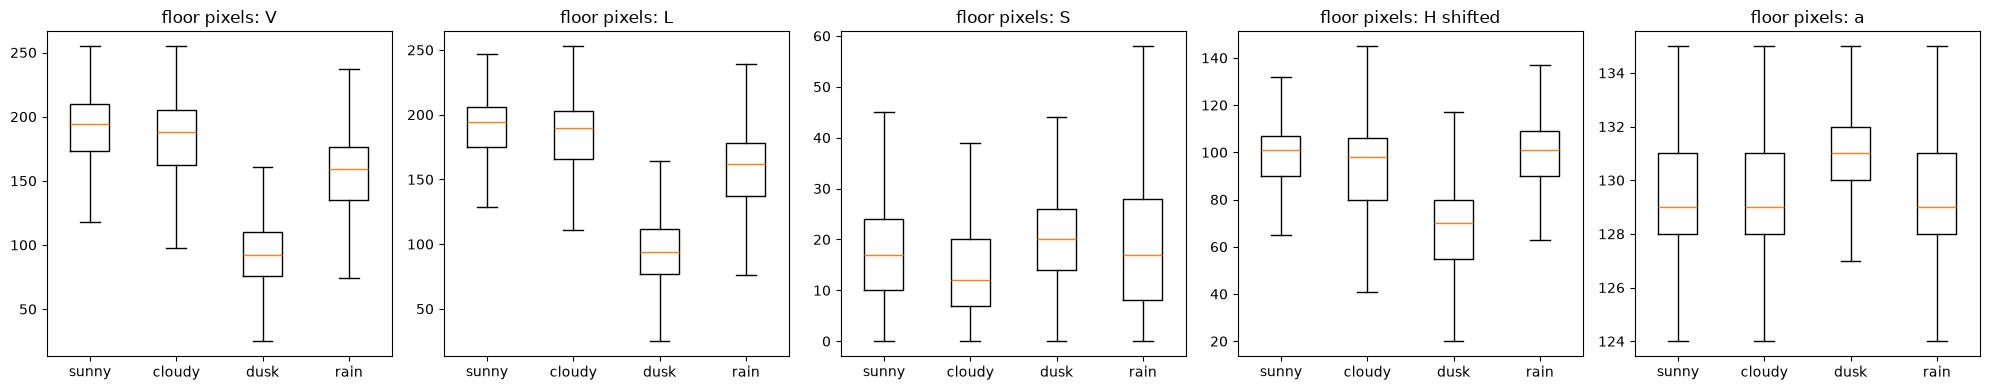

,V,L,S,H shifted,a
weather,,,,,
sunny,194.0,194.0,17.0,101.0,129.0
cloudy,188.0,190.0,12.0,98.0,129.0
dusk,92.0,94.0,20.0,70.0,131.0
rain,159.0,162.0,17.0,101.0,129.0
spread (max - min),102.0,100.0,8.0,31.0,2.0


In [10]:
conditions = [w for w in ['sunny', 'cloudy', 'dusk', 'rain'] if w in set(meta['weather'])]

cond_px = []
for w in conditions:
    for i in np.where(meta['weather'] == w)[0][:6]:          # up to 6 frames per condition, any split
        valid = np.flatnonzero(Y[i] == FLOOR)
        pick = rng.choice(valid, min(10000, len(valid)), replace=False)
        sp = to_spaces(X[i])
        cond_px.append(pd.DataFrame({'weather': w, 'V': sp['V'].ravel()[pick], 'S': sp['S'].ravel()[pick],
                                     'H shifted': (sp['H'].ravel()[pick].astype(int) + 90) % 180,
                                     'L': sp['L'].ravel()[pick], 'a': sp['a'].ravel()[pick]}))
cond_px = pd.concat(cond_px, ignore_index=True)

plt.figure(figsize=(20, 4))
for k, name in enumerate(['V', 'L', 'S', 'H shifted', 'a']):
    plt.subplot(1, 5, k + 1)
    plt.boxplot([cond_px.loc[cond_px['weather'] == w, name] for w in conditions], showfliers=False)
    plt.xticks(range(1, len(conditions) + 1), conditions)
    plt.title(f'floor pixels: {name}')
plt.tight_layout()
plt.show()

medians = cond_px.groupby('weather')[['V', 'L', 'S', 'H shifted', 'a']].median().loc[conditions]
medians.loc['spread (max - min)'] = medians.max() - medians.min()
medians

lantai yang sama terlihat berbeda di setiap kondisi. baris **spread** menunjukkan seberapa jauh median piksel lantai bergeser antar kondisi: kanal dengan spread kecil lebih **tahan terhadap perubahan cahaya**, jadi model yang belajar di hari cerah lebih mungkin tetap benar saat sore atau hujan.

Step 6: CLAHE on V

In [11]:
clahe = cv.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))


def clahe_gray(img):
    return clahe.apply(cv.cvtColor(img, cv.COLOR_BGR2GRAY))


def clahe_v(img):
    hsv = cv.cvtColor(img, cv.COLOR_BGR2HSV)
    hsv[:, :, 2] = clahe.apply(hsv[:, :, 2])   # only V changes, H and S (the colour) stay the same
    return hsv

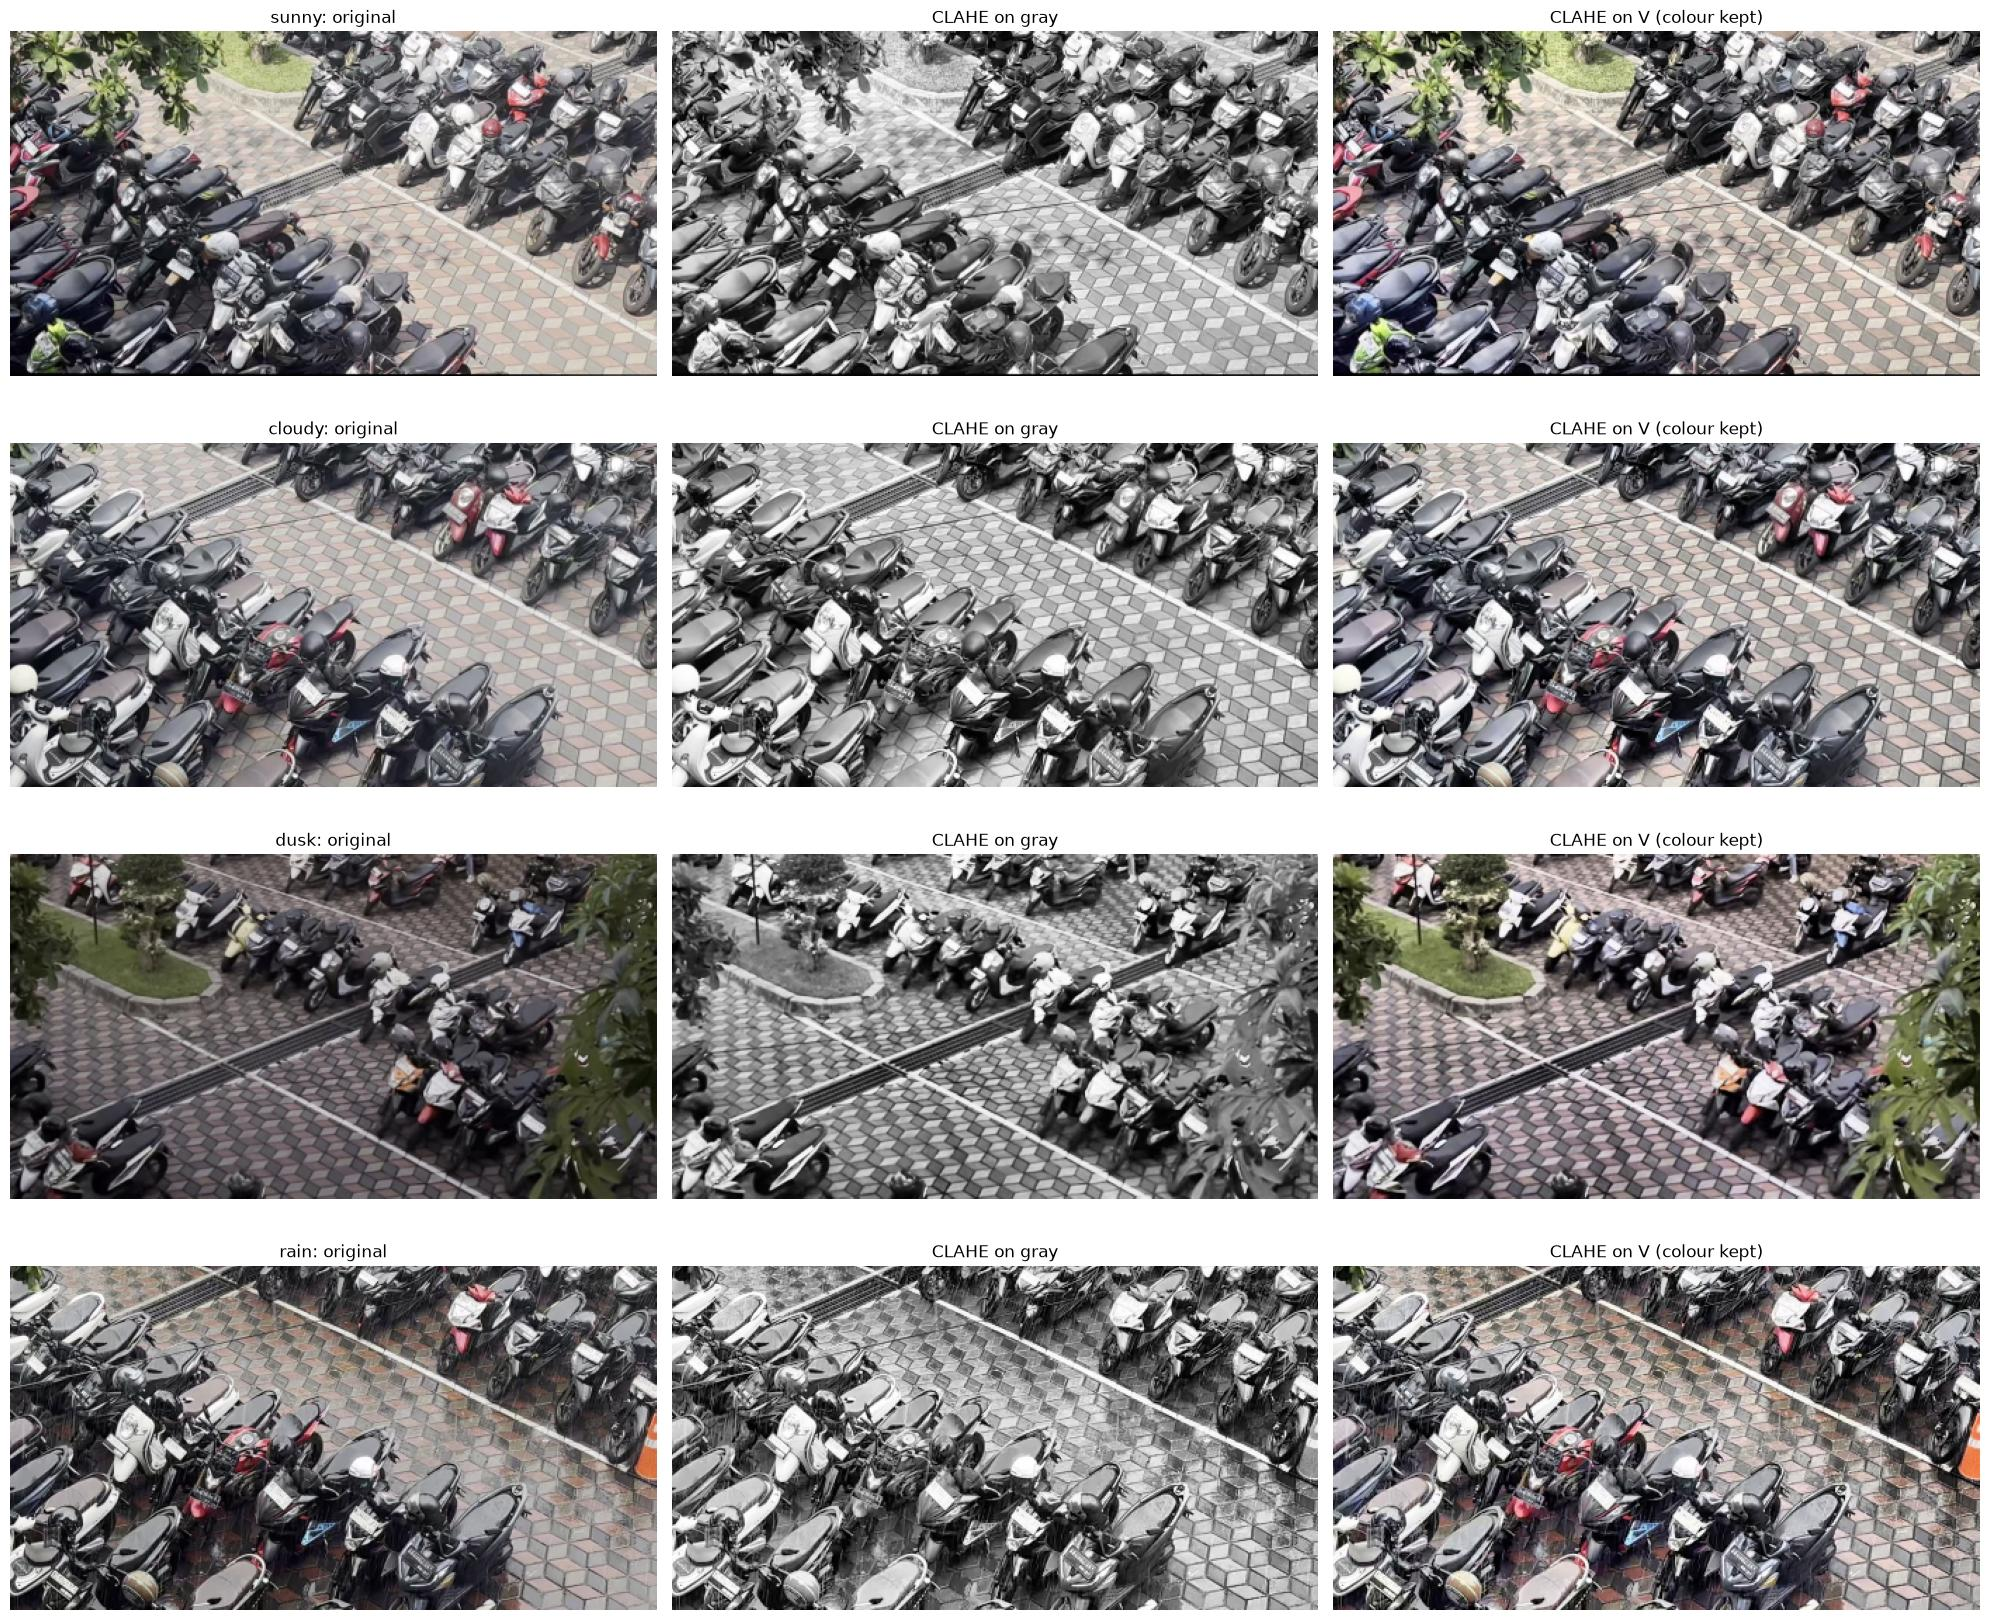

In [12]:
show = [int(np.argmax(meta['weather'] == w)) for w in conditions]

plt.figure(figsize=(20, 4.2 * len(show)))
for r in range(len(show)):
    i = show[r]
    crop = (slice(y0, y0 + 260), slice(x0, x0 + 460))
    plt.subplot(len(show), 3, 3 * r + 1)
    plt.imshow(X[i][crop][:, :, ::-1])
    plt.title(f"{meta['weather'][i]}: original")
    plt.axis('off')
    plt.subplot(len(show), 3, 3 * r + 2)
    plt.imshow(clahe_gray(X[i])[crop], cmap='gray')
    plt.title('CLAHE on gray')
    plt.axis('off')
    plt.subplot(len(show), 3, 3 * r + 3)
    plt.imshow(cv.cvtColor(clahe_v(X[i]), cv.COLOR_HSV2BGR)[crop][:, :, ::-1])
    plt.title('CLAHE on V (colour kept)')
    plt.axis('off')
plt.tight_layout()
plt.show()

In [13]:
v_before, v_after = [], []
for w in conditions:
    for i in np.where(meta['weather'] == w)[0][:6]:
        floor = Y[i] == FLOOR
        v_before.append([w, np.median(cv.cvtColor(X[i], cv.COLOR_BGR2HSV)[:, :, 2][floor])])
        v_after.append([w, np.median(clahe_v(X[i])[:, :, 2][floor])])
v_before = pd.DataFrame(v_before, columns=['weather', 'V']).groupby('weather')['V'].median().loc[conditions]
v_after = pd.DataFrame(v_after, columns=['weather', 'V']).groupby('weather')['V'].median().loc[conditions]

ov_before = overlap(floor_px['V'], motor_px['V'])
clahe_px = []
for i in np.where(meta['split'] == 'train')[0]:
    v = clahe_v(X[i])[:, :, 2]
    clahe_px.append([v[Y[i] == FLOOR][::50], v[Y[i] == MOTOR][::50]])
ov_after = overlap(np.concatenate([c[0] for c in clahe_px]), np.concatenate([c[1] for c in clahe_px]))

print('median V of the floor per condition')
print('  before CLAHE:', v_before.round(0).to_dict(), '-> spread', int(v_before.max() - v_before.min()))
print('  after CLAHE :', v_after.round(0).to_dict(), '-> spread', int(v_after.max() - v_after.min()))
print(f'overlap floor vs motorcycle in V: before {ov_before:.3f}, after CLAHE {ov_after:.3f}')

median V of the floor per condition
  before CLAHE: {'sunny': 194.0, 'cloudy': 188.0, 'dusk': 92.0, 'rain': 160.0} -> spread 102
  after CLAHE : {'sunny': 192.0, 'cloudy': 183.0, 'dusk': 135.0, 'rain': 164.0} -> spread 56
overlap floor vs motorcycle in V: before 0.542, after CLAHE 0.646


**clahe** (contrast limited adaptive histogram equalization) meratakan histogram per tile 8 × 8, dengan batas (clip limit 2.0) supaya noise tidak ikut diperkuat. kalau clahe diterapkan pada grayscale, informasi warna hilang. karena itu clahe diterapkan **hanya pada kanal v**, lalu h dan s dibiarkan, sehingga kontras di bagian gelap (bayangan gedung, sore, hujan) naik tanpa mengubah warna paving dan motor. angka di atas menunjukkan apakah clahe membuat kecerahan lantai di berbagai kondisi menjadi lebih mirip (spread lebih kecil), dan apakah v tetap bisa membedakan lantai dari motor.

Step 7: Noise and Texture

In [14]:
def local_std(channel, size=9):
    # texture: standard deviation of the pixels around each pixel
    c = channel.astype(np.float32)
    mean = cv.blur(c, (size, size))
    mean_sq = cv.blur(c * c, (size, size))
    return np.sqrt(np.maximum(mean_sq - mean * mean, 0))


def edge_density(channel, size=9):
    edges = cv.Canny(channel, 50, 150)
    return cv.blur((edges > 0).astype(np.float32), (size, size))

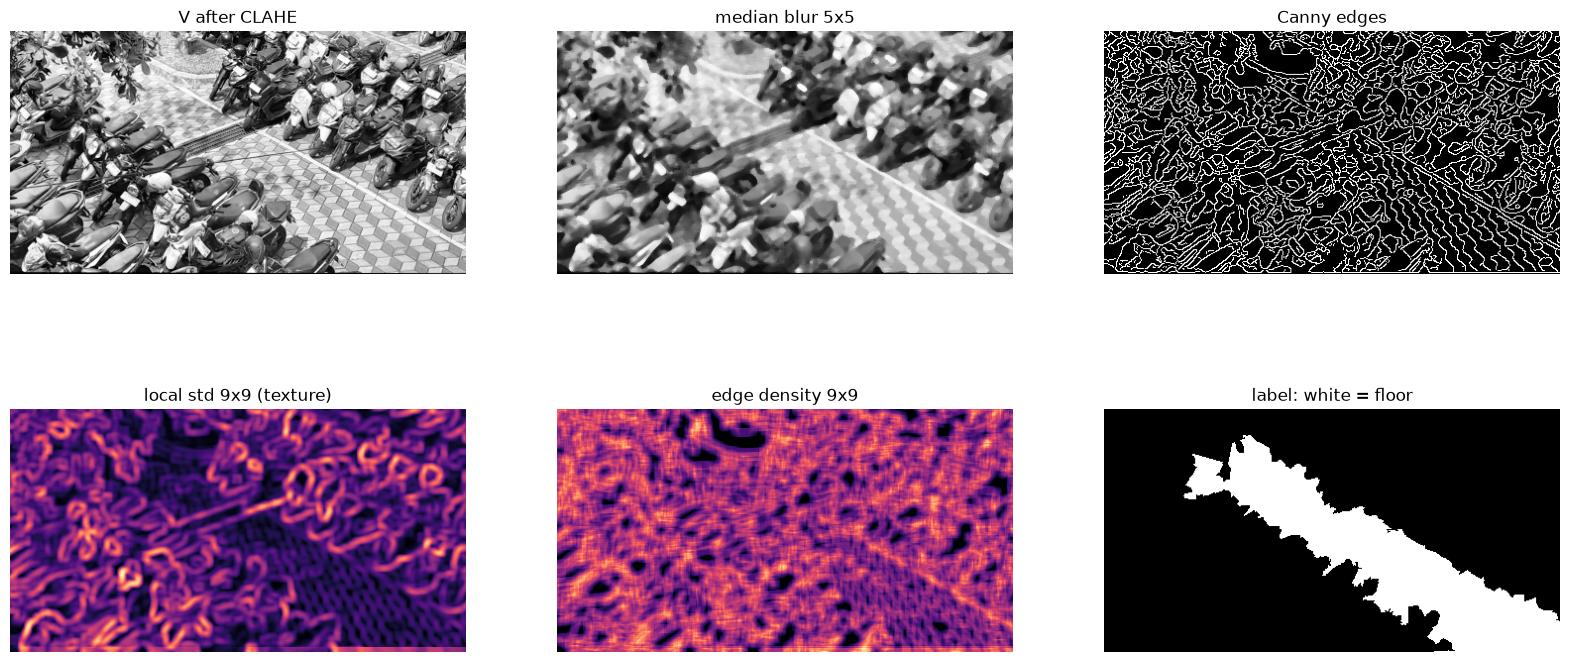

In [15]:
i = DEMO
v = clahe_v(X[i])[:, :, 2]
v_blur = cv.medianBlur(v, 5)
crop = (slice(y0, y0 + 260), slice(x0, x0 + 460))

plt.figure(figsize=(20, 9))
plt.subplot(2, 3, 1)
plt.imshow(v[crop], cmap='gray')
plt.title('V after CLAHE')
plt.axis('off')
plt.subplot(2, 3, 2)
plt.imshow(v_blur[crop], cmap='gray')
plt.title('median blur 5x5')
plt.axis('off')
plt.subplot(2, 3, 3)
plt.imshow(cv.Canny(v_blur, 50, 150)[crop], cmap='gray')
plt.title('Canny edges')
plt.axis('off')
plt.subplot(2, 3, 4)
plt.imshow(local_std(v_blur)[crop], cmap='magma')
plt.title('local std 9x9 (texture)')
plt.axis('off')
plt.subplot(2, 3, 5)
plt.imshow(edge_density(v_blur)[crop], cmap='magma')
plt.title('edge density 9x9')
plt.axis('off')
plt.subplot(2, 3, 6)
plt.imshow(cv.cvtColor(np.uint8(Y[i] == FLOOR) * 255, cv.COLOR_GRAY2RGB)[crop])
plt.title('label: white = floor')
plt.axis('off')
plt.show()

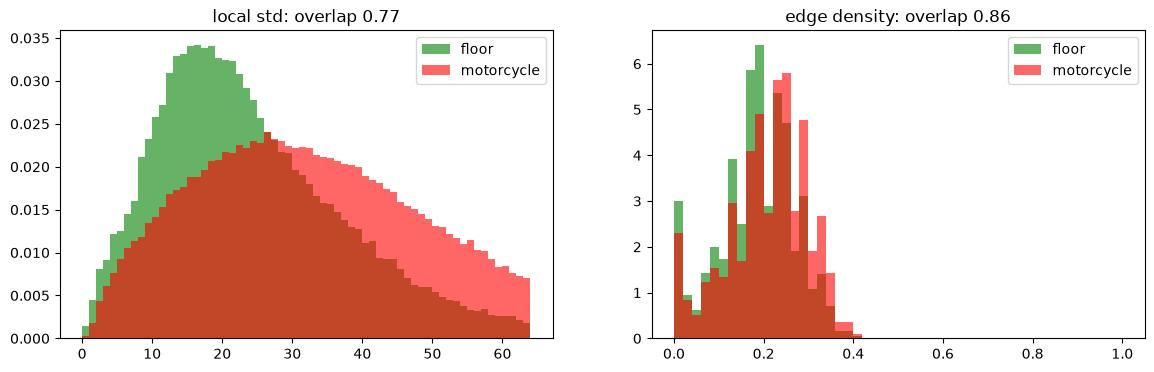

In [16]:
tex_floor, tex_motor, ed_floor, ed_motor = [], [], [], []
for i in np.where(meta['split'] == 'train')[0]:
    v_blur = cv.medianBlur(clahe_v(X[i])[:, :, 2], 5)
    t, e = local_std(v_blur), edge_density(v_blur)
    tex_floor.append(t[Y[i] == FLOOR][::50])
    tex_motor.append(t[Y[i] == MOTOR][::50])
    ed_floor.append(e[Y[i] == FLOOR][::50])
    ed_motor.append(e[Y[i] == MOTOR][::50])
tex_floor, tex_motor = np.concatenate(tex_floor), np.concatenate(tex_motor)
ed_floor, ed_motor = np.concatenate(ed_floor), np.concatenate(ed_motor)

plt.figure(figsize=(14, 4))
plt.subplot(1, 2, 1)
plt.hist(tex_floor, bins=64, range=(0, 64), density=True, alpha=0.6, color='green', label='floor')
plt.hist(tex_motor, bins=64, range=(0, 64), density=True, alpha=0.6, color='red', label='motorcycle')
plt.title(f'local std: overlap {overlap(tex_floor, tex_motor, value_range=(0, 64)):.2f}')
plt.legend()
plt.subplot(1, 2, 2)
plt.hist(ed_floor, bins=50, range=(0, 1), density=True, alpha=0.6, color='green', label='floor')
plt.hist(ed_motor, bins=50, range=(0, 1), density=True, alpha=0.6, color='red', label='motorcycle')
plt.title(f'edge density: overlap {overlap(ed_floor, ed_motor, bins=50, value_range=(0, 1)):.2f}')
plt.legend()
plt.show()

**median blur** 5 × 5 menghapus noise kecil (bintik terang, pantulan) tapi tetap menjaga tepi, karena setiap piksel diganti dengan median tetangga nya, bukan rata-rata. lalu dihitung dua fitur tekstur:

- **local std**: simpangan baku kecerahan di jendela 9 × 9. lantai paving punya pola hexagon yang teratur dan kontras nya sedang, sedangkan motor punya pantulan terang dan bagian hitam yang bersebelahan, jadi local std nya tinggi.
- **edge density**: persentase piksel tepi canny di jendela 9 × 9.

fitur ini melengkapi warna. ubin abu-abu dan motor silver bisa punya h, s dan v yang mirip, tapi tekstur nya berbeda.

Step 8: Baseline Segmentation (Naive Bayes on HSV + Texture)

In [17]:
H_BINS, S_BINS, T_BINS = 30, 32, 32


def pcd_features(img):
    hsv = clahe_v(img)
    hsv[:, :, 2] = cv.medianBlur(hsv[:, :, 2], 5)
    h_bin = np.minimum(hsv[:, :, 0].astype(int) * H_BINS // 180, H_BINS - 1)
    s_bin = np.minimum(hsv[:, :, 1].astype(int) * S_BINS // 256, S_BINS - 1)
    t_bin = np.minimum(local_std(hsv[:, :, 2]).astype(int) * T_BINS // 64, T_BINS - 1)
    return h_bin, s_bin, t_bin


def fit_histograms(split):
    # count how often every (H, S) bin and every texture bin appears in floor and in motorcycle pixels
    hs = np.ones((2, H_BINS, S_BINS))   # start at 1 so no bin has probability 0
    tex = np.ones((2, T_BINS))
    for i in np.where(meta['split'] == split)[0]:
        h_bin, s_bin, t_bin = pcd_features(X[i])
        for cls in [FLOOR, MOTOR]:
            m = Y[i] == cls
            np.add.at(hs[cls], (h_bin[m], s_bin[m]), 1)
            np.add.at(tex[cls], t_bin[m], 1)
    prior = np.array([hs[FLOOR].sum(), hs[MOTOR].sum()])
    return hs / hs.sum(axis=(1, 2), keepdims=True), tex / tex.sum(axis=1, keepdims=True), prior / prior.sum()


def log_ratio(img, model, use_texture):
    # log P(floor | pixel) - log P(motorcycle | pixel), assuming colour and texture are independent
    p_hs, p_tex, prior = model
    h_bin, s_bin, t_bin = pcd_features(img)
    score = np.log(p_hs[FLOOR][h_bin, s_bin]) - np.log(p_hs[MOTOR][h_bin, s_bin]) + np.log(prior[FLOOR] / prior[MOTOR])
    if use_texture:
        score += np.log(p_tex[FLOOR][t_bin]) - np.log(p_tex[MOTOR][t_bin])
    return score

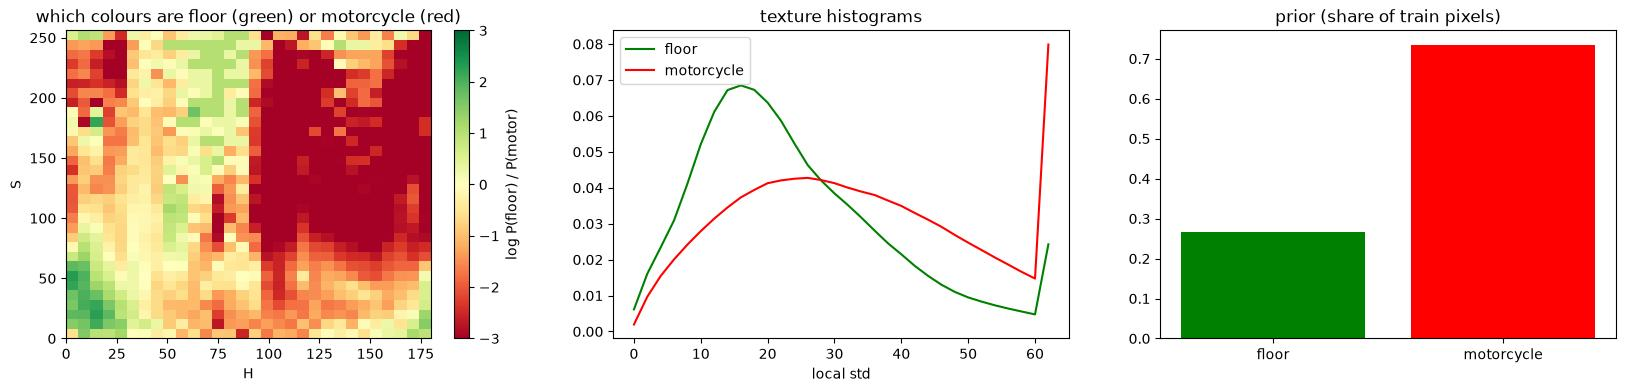

In [18]:
model = fit_histograms('train')
p_hs, p_tex, prior = model

plt.figure(figsize=(20, 4))
plt.subplot(1, 3, 1)
plt.imshow(np.log(p_hs[FLOOR] / p_hs[MOTOR]).T, origin='lower', cmap='RdYlGn', vmin=-3, vmax=3, aspect='auto',
           extent=[0, 180, 0, 256])
plt.colorbar(label='log P(floor) / P(motor)')
plt.xlabel('H')
plt.ylabel('S')
plt.title('which colours are floor (green) or motorcycle (red)')
plt.subplot(1, 3, 2)
plt.plot(np.arange(T_BINS) * 64 / T_BINS, p_tex[FLOOR], color='green', label='floor')
plt.plot(np.arange(T_BINS) * 64 / T_BINS, p_tex[MOTOR], color='red', label='motorcycle')
plt.xlabel('local std')
plt.title('texture histograms')
plt.legend()
plt.subplot(1, 3, 3)
plt.bar(['floor', 'motorcycle'], prior, color=['green', 'red'])
plt.title('prior (share of train pixels)')
plt.show()

In [19]:
def predict(img, roi, model, use_texture, threshold, morphology):
    pred = np.where(log_ratio(img, model, use_texture) > threshold, FLOOR, MOTOR).astype(np.uint8)
    if morphology:
        floor = np.uint8(pred == FLOOR)
        kernel = cv.getStructuringElement(cv.MORPH_ELLIPSE, (7, 7))
        floor = cv.morphologyEx(floor, cv.MORPH_OPEN, kernel)    # remove small floor specks on motorcycles
        floor = cv.morphologyEx(floor, cv.MORPH_CLOSE, kernel)   # fill small holes in the floor
        pred = np.where(floor == 1, FLOOR, MOTOR).astype(np.uint8)
    pred[roi == 0] = IGNORE
    return pred


def evaluate(preds, idx):
    # IoU per class summed over all frames, plus pixel accuracy
    inter, union, correct, total = np.zeros(2), np.zeros(2), 0, 0
    for p, i in zip(preds, idx):
        valid = Y[i] != IGNORE
        for cls in [FLOOR, MOTOR]:
            inter[cls] += np.sum((p == cls) & (Y[i] == cls) & valid)
            union[cls] += np.sum(((p == cls) | (Y[i] == cls)) & valid)
        correct += np.sum((p == Y[i]) & valid)
        total += np.sum(valid)
    iou = inter / np.maximum(union, 1)
    return {'IoU floor': iou[FLOOR], 'IoU motor': iou[MOTOR], 'mIoU': iou.mean(), 'pixel acc': correct / total}

HS                           best threshold on val = -0.5 (val mIoU 0.703)


HS + texture                 best threshold on val = -1.0 (val mIoU 0.706)


HS + texture + morphology    best threshold on val = -1.5 (val mIoU 0.754)


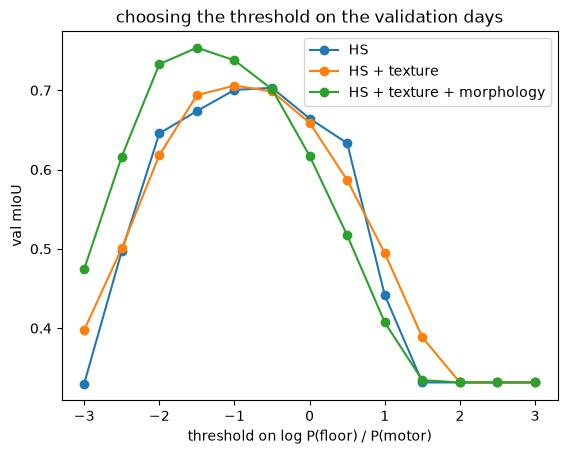

In [20]:
val_idx = np.where(meta['split'] == 'val')[0]
test_idx = np.where(meta['split'] == 'test')[0]


def roi_of(i):
    return geo[meta['video_id'][i]]['roi_mask']


variants = [('HS', False, False), ('HS + texture', True, False), ('HS + texture + morphology', True, True)]
thresholds = np.arange(-3, 3.01, 0.5)

best = {}
for name, use_texture, morphology in variants:
    val_miou = []
    for t in thresholds:
        preds = [predict(X[i], roi_of(i), model, use_texture, t, morphology) for i in val_idx]
        val_miou.append(evaluate(preds, val_idx)['mIoU'])
    best[name] = thresholds[int(np.argmax(val_miou))]
    plt.plot(thresholds, val_miou, 'o-', label=name)
    print(f'{name:28s} best threshold on val = {best[name]:+.1f} (val mIoU {max(val_miou):.3f})')
plt.xlabel('threshold on log P(floor) / P(motor)')
plt.ylabel('val mIoU')
plt.title('choosing the threshold on the validation days')
plt.legend()
plt.show()

In [21]:
results, test_preds = [], {}
for name, use_texture, morphology in variants:
    preds = [predict(X[i], roi_of(i), model, use_texture, best[name], morphology) for i in test_idx]
    test_preds[name] = preds
    r = evaluate(preds, test_idx)
    results.append([name, best[name]] + [round(r[k], 3) for k in ['IoU floor', 'IoU motor', 'mIoU', 'pixel acc']])
results = pd.DataFrame(results, columns=['variant', 'threshold', 'IoU floor', 'IoU motor', 'mIoU', 'pixel acc'])
results

,variant,threshold,IoU floor,IoU motor,mIoU,pixel acc
0,HS,-0.5,0.452,0.726,0.589,0.777
1,HS + texture,-1.0,0.480,0.708,0.594,0.770
2,HS + texture + morphology,-1.5,0.537,0.757,0.647,0.811


sebagai baseline pcd murni (tanpa machine learning yang rumit), setiap piksel diklasifikasi dengan **naive bayes**: dari piksel train dihitung histogram (h, s) dan histogram tekstur untuk lantai dan untuk motor. untuk piksel baru, nilai log P(lantai) − log P(motor) dihitung dari kedua histogram (dianggap independen) ditambah prior nya. kalau nilai nya di atas threshold, piksel dianggap lantai. ini sama dengan **histogram back-projection** yang biasa dipakai di opencv (`cv.calcBackProject`), tapi dengan dua kelas. v tidak dipakai langsung karena paling terpengaruh cahaya, tapi v hasil clahe dipakai untuk menghitung tekstur.

threshold dipilih di hari **val**, lalu ketiga varian dibandingkan di hari **test**:
- **HS**: warna saja
- **HS + texture**: warna dan local std
- **HS + texture + morphology**: ditambah opening (hapus bintik lantai kecil di badan motor) dan closing (tutup lubang kecil di lantai) dengan kernel elips 7 × 7

Step 9: Free Spaces from the Predicted Mask

In [22]:
def count_free_spaces(mask, g):
    floor = (mask == FLOOR).astype(np.uint8)
    floor_bev = cv.warpPerspective(floor, g['H'], g['size'], flags=cv.INTER_NEAREST) * g['roi_bev']
    usable = cv.morphologyEx(floor_bev, cv.MORPH_OPEN, g['kernel'])
    n, labels, comp_stats, _ = cv.connectedComponentsWithStats(usable)
    free = 0
    for c in range(1, n):
        free += max(1, int(round(comp_stats[c, cv.CC_STAT_AREA] / g['motor_area'])))
    return free

In [23]:
free_table = meta.loc[test_idx, ['frame', 'weather', 'free spaces']].rename(columns={'free spaces': 'label'}).reset_index(drop=True)
for name, use_texture, morphology in variants:
    free_table[name] = [count_free_spaces(p, geo[meta['video_id'][i]]) for p, i in zip(test_preds[name], test_idx)]

mae = {name: float(np.mean(np.abs(free_table[name] - free_table['label']))) for name, _, _ in variants}
results['MAE free spaces'] = [round(mae[name], 2) for name, _, _ in variants]
print('MAE of the free-space count on the test days:', {k: round(v, 2) for k, v in mae.items()})
free_table

MAE of the free-space count on the test days: {'HS': 15.12, 'HS + texture': 10.12, 'HS + texture + morphology': 12.81}


,frame,weather,label,HS,HS + texture,HS + texture + morphology
0,20261104_afternoon_dinda_t000.jpg,sunny,30,20,33,56
1,20261104_afternoon_dinda_t015.jpg,sunny,39,25,39,58
2,20261104_afternoon_dinda_t030.jpg,sunny,41,19,36,58
3,20261104_afternoon_dinda_t045.jpg,sunny,44,21,36,63
4,20261104_afternoon_dinda_t060.jpg,sunny,36,22,35,58
5,20261104_afternoon_dinda_t075.jpg,sunny,30,27,37,63
6,20261104_afternoon_dinda_t090.jpg,sunny,25,19,33,53
7,20261104_afternoon_dinda_t105.jpg,sunny,21,14,25,43
8,20261104_afternoon_dinda_t120.jpg,sunny,31,22,37,56
9,20261104_evening_keiza_t000.jpg,dusk,25,2,4,13


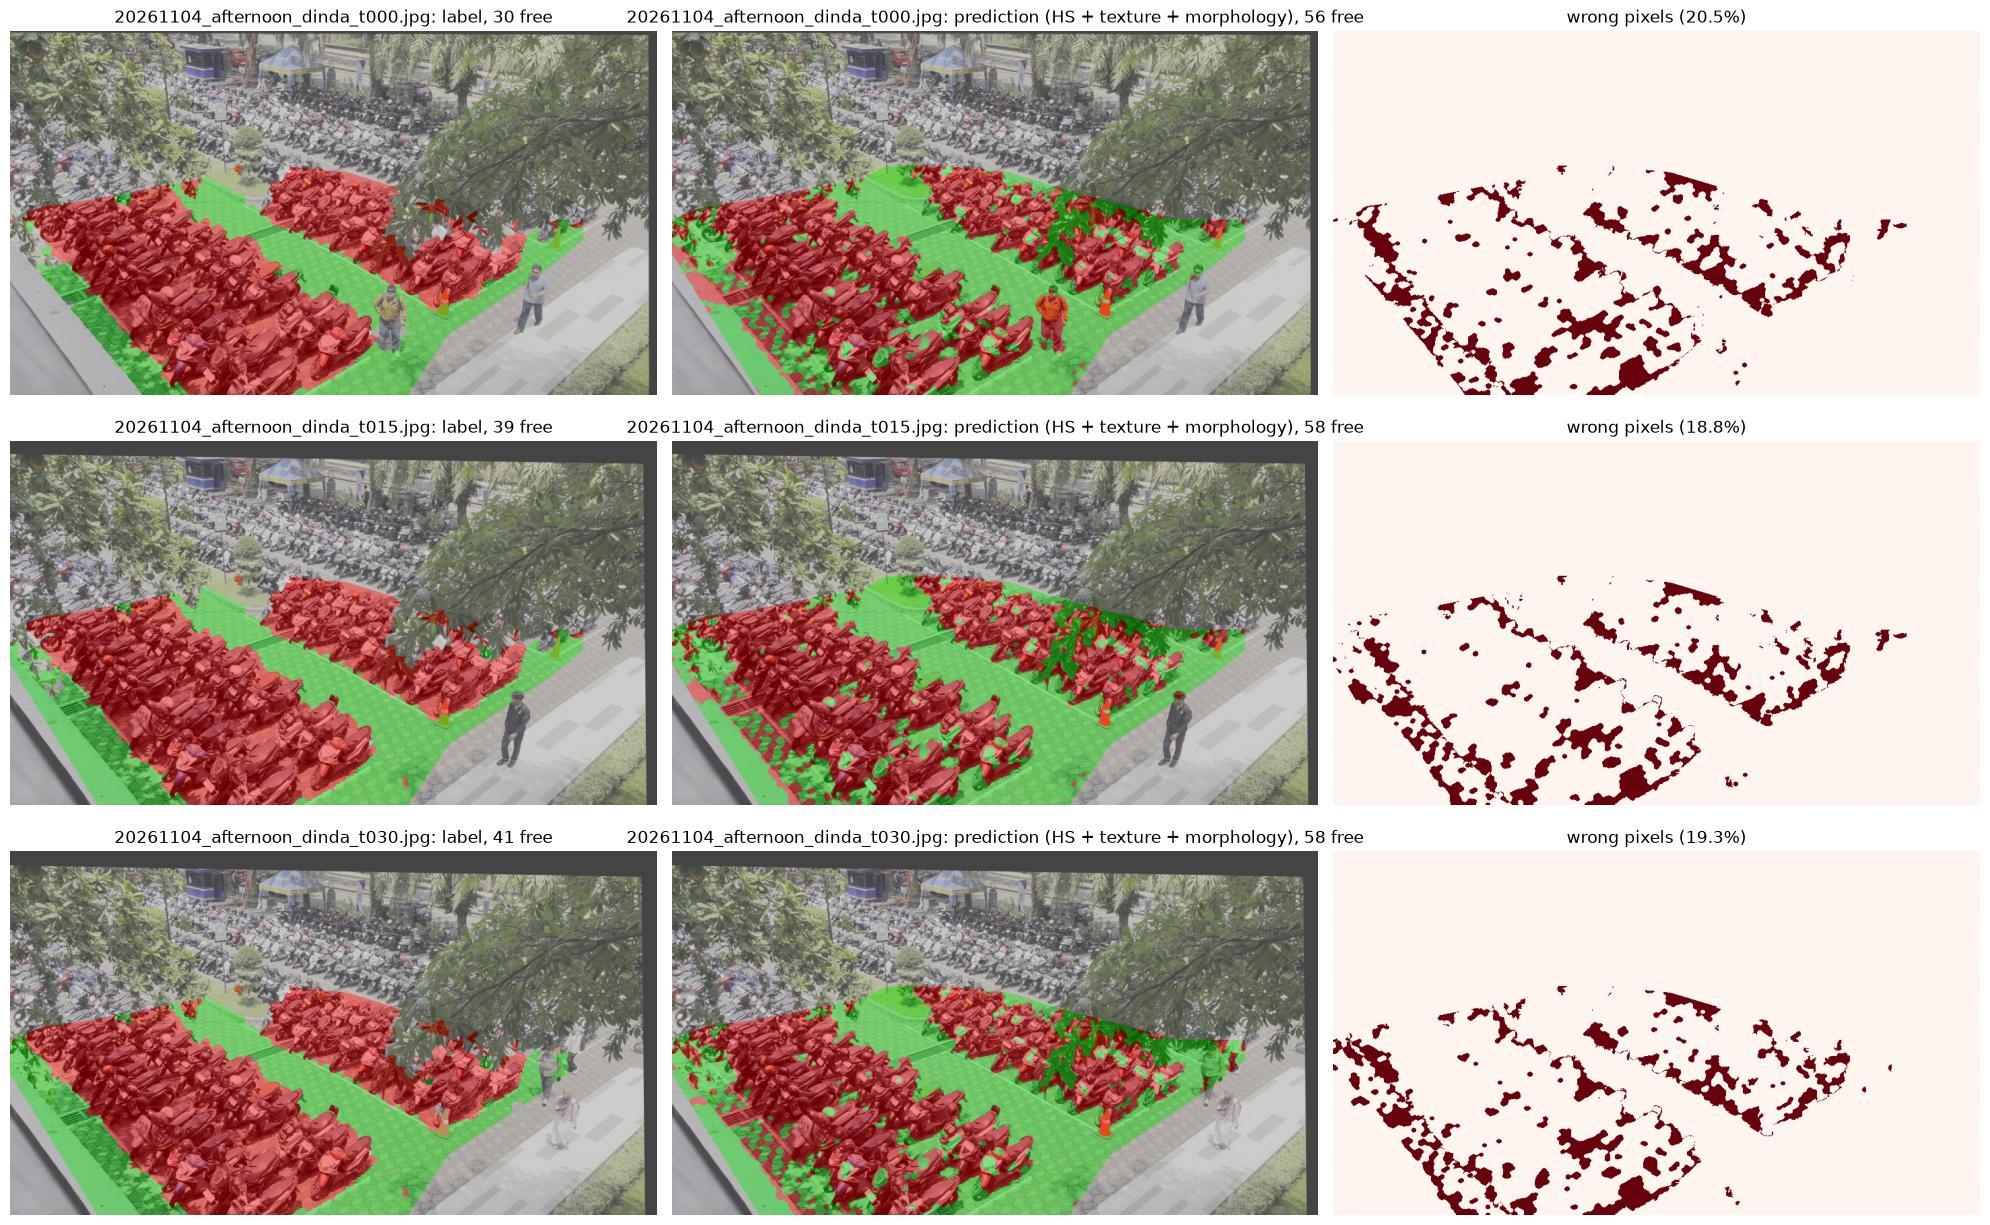

In [24]:
BEST = results.sort_values('mIoU', ascending=False)['variant'].iloc[0]
show = test_idx[:3]

plt.figure(figsize=(20, 4.2 * len(show)))
for r in range(len(show)):
    i = show[r]
    k = list(test_idx).index(i)
    for c, (mask, title) in enumerate([(Y[i], 'label'), (test_preds[BEST][k], f'prediction ({BEST})')]):
        color = np.zeros_like(X[i])
        for cls in CLASS_COLORS:
            color[mask == cls] = CLASS_COLORS[cls]
        plt.subplot(len(show), 3, 3 * r + c + 1)
        plt.imshow(cv.addWeighted(color, 0.45, X[i], 0.55, 0)[:, :, ::-1])
        free = count_free_spaces(mask, geo[meta['video_id'][i]])
        plt.title(f"{meta['frame'][i]}: {title}, {free} free")
        plt.axis('off')
    err = (test_preds[BEST][k] != Y[i]) & (Y[i] != IGNORE)
    plt.subplot(len(show), 3, 3 * r + 3)
    plt.imshow(err, cmap='Reds')
    plt.title(f'wrong pixels ({100 * err.sum() / np.sum(Y[i] != IGNORE):.1f}%)')
    plt.axis('off')
plt.tight_layout()
plt.show()

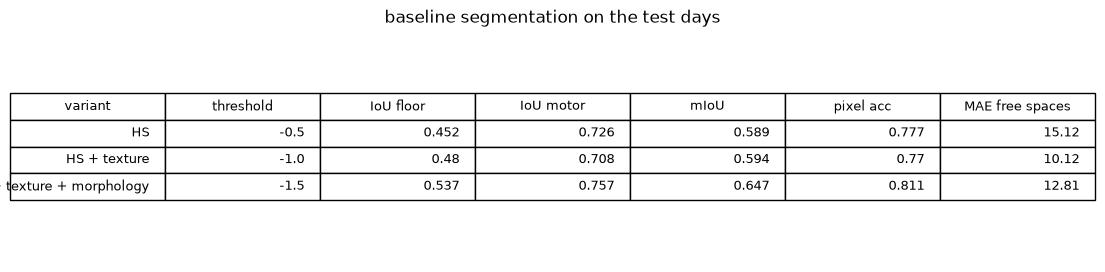

In [25]:
plt.figure(figsize=(14, 3))
table = plt.table(cellText=results.values.tolist(), colLabels=list(results.columns), loc='center')
table.auto_set_font_size(False)
table.set_fontsize(9)
table.scale(1, 1.6)
plt.title('baseline segmentation on the test days')
plt.axis('off')
plt.show()

mask prediksi diproses dengan `count_free_spaces` yang sama seperti mask label (bird's-eye view → opening dengan tapak motor → luas ÷ luas satu motor), jadi selain **iou** per piksel, error nya juga bisa diukur dalam satuan yang penting untuk pengguna: **mae jumlah ruang kosong** per frame.

Step 10: Save the PCD Dataset

In [26]:
def pcd_image(img):
    # chosen PCD: BGR -> HSV, CLAHE on V, median blur on V
    hsv = clahe_v(img)
    hsv[:, :, 2] = cv.medianBlur(hsv[:, :, 2], 5)
    return hsv


X_pcd = np.stack([pcd_image(X[i]) for i in range(len(X))])
with open(PCD_PKL, 'wb') as f:
    pickle.dump({'X': X_pcd, 'Y': Y, 'meta': meta, 'geo': geo, 'classes': data['classes'],
                 'info': 'X = HSV (H 0-179, S, V after CLAHE clip 2.0 tiles 8x8 + median blur 5) uint8 960x540; '
                         'Y, meta, geo exactly as in dataset_seg.pkl'}, f)
print('X_pcd:', X_pcd.shape, X_pcd.dtype)
print('saved', PCD_PKL, f'({PCD_PKL.stat().st_size / 1e6:.0f} MB)')

X_pcd: (92, 540, 960, 3) uint8
saved C:\Users\ASUS\.vscode\pcd\project-akhir\data\processed\dataset_pcd.pkl (201 MB)


`dataset_pcd.pkl` berisi frame yang sama dengan `dataset_seg.pkl`, tetapi sudah melalui pcd yang dipilih: **bgr → hsv → clahe pada v → median blur pada v**. `Y`, `meta` dan `geo` sama persis, jadi eksperimen raw (B) dan pcd (C) memakai label, split dan cara menghitung ruang kosong yang sama, dan yang berbeda hanya input nya.